# 27 — Final Date-Block Bootstrap
## Temporal-dependence-aware uncertainty for Emerging-3 enrichment

### Why this notebook exists

The frozen anomaly model and candidate rule are already final.

NB26 showed that:
- Emerging-3: 118 / 217 robust candidates;
- Persistent: 476 / 1849 robust candidates;
- observed candidate-rate ratio ≈ 2.11×.

A simple Fisher exact test and an IID confidence interval treat individual cell-day observations as independent.

That assumption is too strong for spatiotemporal hotspot data because many observations occurring on the same date can share meteorological, regional, and fire-regime conditions.

Therefore this notebook uses a **date-block bootstrap**:

1. aggregate event counts and candidate counts by date and research group;
2. resample whole dates with replacement;
3. preserve all observations belonging to each selected date;
4. recompute candidate rates, risk ratio, and risk difference;
5. repeat many times.

This provides uncertainty estimates that respect within-date dependence better than row-wise resampling.

### Important

This is still post-hoc validation of model behavior.

`Emerging-3` and `Persistent` are not ground-truth anomaly classes and are not ignition-cause labels.

In [2]:
# 1. Imports

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 300)

In [3]:
# 2. Resolve project root and frozen NB25 analysis export

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    analysis_path = (
        root
        / "model_results"
        / "final_masked_temporal_anomaly"
        / "t2"
        / "exports"
        / "august_hotspot_candidate_analysis.csv"
    )

    if analysis_path.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate NB25 august_hotspot_candidate_analysis.csv. "
        "Run NB25 successfully first."
    )

ANALYSIS_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "final_masked_temporal_anomaly"
    / "t2"
    / "exports"
    / "august_hotspot_candidate_analysis.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "final_date_block_bootstrap"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("ANALYSIS_PATH:", ANALYSIS_PATH)
print("RESULT_DIR:", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
ANALYSIS_PATH: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_masked_temporal_anomaly\t2\exports\august_hotspot_candidate_analysis.csv
RESULT_DIR: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_date_block_bootstrap\t2


In [4]:
# 3. Load frozen hotspot analysis

analysis = pd.read_csv(
    ANALYSIS_PATH,
    parse_dates=["event_date"],
)

known = (
    analysis[
        analysis[
            "research_group"
        ].isin(
            [
                "Emerging-3",
                "Persistent",
            ]
        )
    ]
    .copy()
)

known[
    "robust_anomaly_candidate"
] = (
    known[
        "robust_anomaly_candidate"
    ]
    .astype(bool)
)

print("Known-group hotspot rows:", len(known))
print("Unique dates:", known["event_date"].nunique())

display(
    known[
        "research_group"
    ].value_counts()
    .rename_axis("research_group")
    .reset_index(name="events")
)

Known-group hotspot rows: 2066
Unique dates: 29


,research_group,events
0,Persistent,1849
1,Emerging-3,217


# PART A — Observed effect sizes

The primary descriptive effects are:

- Emerging-3 candidate rate;
- Persistent candidate rate;
- candidate-rate ratio (`Emerging / Persistent`);
- candidate-rate difference (`Emerging - Persistent`).

The bootstrap will estimate uncertainty around these same frozen quantities.

In [5]:
# 4. Metric helper

def compute_metrics_from_counts(
    em_events,
    em_candidates,
    pe_events,
    pe_candidates,
):
    em_rate = (
        em_candidates / em_events
        if em_events > 0
        else np.nan
    )

    pe_rate = (
        pe_candidates / pe_events
        if pe_events > 0
        else np.nan
    )

    risk_ratio = (
        em_rate / pe_rate
        if (
            np.isfinite(em_rate)
            and np.isfinite(pe_rate)
            and pe_rate > 0
        )
        else np.nan
    )

    risk_difference = (
        em_rate - pe_rate
        if (
            np.isfinite(em_rate)
            and np.isfinite(pe_rate)
        )
        else np.nan
    )

    return {
        "emerging_rate": em_rate,
        "persistent_rate": pe_rate,
        "risk_ratio": risk_ratio,
        "risk_difference": risk_difference,
    }

In [6]:
# 5. Observed counts and metrics

group_observed = (
    known
    .groupby("research_group")
    .agg(
        events=(
            "cell_id",
            "size",
        ),
        candidates=(
            "robust_anomaly_candidate",
            "sum",
        ),
    )
)

em_events = int(
    group_observed.loc[
        "Emerging-3",
        "events",
    ]
)

em_candidates = int(
    group_observed.loc[
        "Emerging-3",
        "candidates",
    ]
)

pe_events = int(
    group_observed.loc[
        "Persistent",
        "events",
    ]
)

pe_candidates = int(
    group_observed.loc[
        "Persistent",
        "candidates",
    ]
)

observed = compute_metrics_from_counts(
    em_events,
    em_candidates,
    pe_events,
    pe_candidates,
)

observed_table = pd.DataFrame({
    "group": [
        "Emerging-3",
        "Persistent",
    ],
    "events": [
        em_events,
        pe_events,
    ],
    "robust_candidates": [
        em_candidates,
        pe_candidates,
    ],
    "candidate_rate": [
        observed["emerging_rate"],
        observed["persistent_rate"],
    ],
})

display(observed_table)

print()
print(
    "Observed risk ratio:",
    round(
        observed["risk_ratio"],
        4,
    ),
)

print(
    "Observed risk difference:",
    round(
        observed["risk_difference"],
        4,
    ),
)

,group,events,robust_candidates,candidate_rate
0,Emerging-3,217,118,0.543779
1,Persistent,1849,476,0.257436



Observed risk ratio: 2.1123
Observed risk difference: 0.2863


# PART B — Aggregate into whole-date blocks

We aggregate first instead of repeatedly concatenating raw rows.

For every date and group we keep:

- number of hotspot cell-days;
- number of robust candidates.

When a date is resampled, all counts from that date are carried together.

In [7]:
# 6. Date × research-group count table

daily_counts_long = (
    known
    .groupby(
        [
            "event_date",
            "research_group",
        ]
    )
    .agg(
        events=(
            "cell_id",
            "size",
        ),
        candidates=(
            "robust_anomaly_candidate",
            "sum",
        ),
    )
    .reset_index()
)

all_dates = np.array(
    sorted(
        known[
            "event_date"
        ]
        .dropna()
        .unique()
    )
)

daily_lookup = {}

for d in all_dates:
    day = (
        daily_counts_long[
            daily_counts_long[
                "event_date"
            ].eq(d)
        ]
        .set_index(
            "research_group"
        )
    )

    daily_lookup[d] = {
        "em_events": int(
            day.loc[
                "Emerging-3",
                "events",
            ]
        )
        if "Emerging-3" in day.index
        else 0,
        "em_candidates": int(
            day.loc[
                "Emerging-3",
                "candidates",
            ]
        )
        if "Emerging-3" in day.index
        else 0,
        "pe_events": int(
            day.loc[
                "Persistent",
                "events",
            ]
        )
        if "Persistent" in day.index
        else 0,
        "pe_candidates": int(
            day.loc[
                "Persistent",
                "candidates",
            ]
        )
        if "Persistent" in day.index
        else 0,
    }

print("Date blocks:", len(all_dates))

display(
    daily_counts_long.head(20)
)

Date blocks: 29


,event_date,research_group,events,candidates
0,2026-08-02,Emerging-3,4,4
1,2026-08-02,Persistent,31,17
2,2026-08-04,Emerging-3,5,5
3,2026-08-04,Persistent,18,13
4,2026-08-05,Emerging-3,30,12
5,2026-08-05,Persistent,31,12
6,2026-08-06,Emerging-3,17,13
7,2026-08-06,Persistent,44,12
8,2026-08-07,Emerging-3,10,8
9,2026-08-07,Persistent,50,17


# PART C — Primary date-block bootstrap

Locked settings:

- 10,000 bootstrap replicates;
- sample exactly the observed number of unique dates;
- sample dates **with replacement**;
- preserve all rows/counts within selected dates;
- percentile 95% confidence intervals.

We do not change these settings based on the result.

In [8]:
# 7. Date-block bootstrap

N_BOOT = 10_000
BOOT_SEED = 2026

rng = np.random.default_rng(
    BOOT_SEED
)

boot_rows = []

n_dates = len(all_dates)

for i in range(N_BOOT):
    sampled_dates = rng.choice(
        all_dates,
        size=n_dates,
        replace=True,
    )

    em_n_b = 0
    em_c_b = 0
    pe_n_b = 0
    pe_c_b = 0

    for d in sampled_dates:
        values = daily_lookup[d]

        em_n_b += values[
            "em_events"
        ]

        em_c_b += values[
            "em_candidates"
        ]

        pe_n_b += values[
            "pe_events"
        ]

        pe_c_b += values[
            "pe_candidates"
        ]

    metrics = compute_metrics_from_counts(
        em_n_b,
        em_c_b,
        pe_n_b,
        pe_c_b,
    )

    boot_rows.append({
        "bootstrap_id": i,
        "emerging_events": em_n_b,
        "emerging_candidates": em_c_b,
        "persistent_events": pe_n_b,
        "persistent_candidates": pe_c_b,
        **metrics,
    })

bootstrap = pd.DataFrame(
    boot_rows
)

print("Bootstrap replicates:", len(bootstrap))

print(
    "Finite risk-ratio replicates:",
    bootstrap[
        "risk_ratio"
    ].notna().sum(),
)

Bootstrap replicates: 10000
Finite risk-ratio replicates: 10000


In [9]:
# 8. Percentile confidence intervals

def percentile_ci(
    series,
    lower=0.025,
    upper=0.975,
):
    values = (
        pd.Series(series)
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    return (
        float(
            np.quantile(
                values,
                lower,
            )
        ),
        float(
            np.quantile(
                values,
                upper,
            )
        ),
    )


summary_rows = []

metric_map = {
    "emerging_rate": (
        "Emerging-3 candidate rate",
        observed[
            "emerging_rate"
        ],
    ),
    "persistent_rate": (
        "Persistent candidate rate",
        observed[
            "persistent_rate"
        ],
    ),
    "risk_ratio": (
        "Candidate-rate ratio Emerging/Persistent",
        observed[
            "risk_ratio"
        ],
    ),
    "risk_difference": (
        "Candidate-rate difference Emerging-Persistent",
        observed[
            "risk_difference"
        ],
    ),
}

for col, (
    label,
    observed_value,
) in metric_map.items():
    low, high = percentile_ci(
        bootstrap[col]
    )

    summary_rows.append({
        "metric": label,
        "observed": float(
            observed_value
        ),
        "bootstrap_2.5%": low,
        "bootstrap_97.5%": high,
        "bootstrap_replicates": int(
            bootstrap[
                col
            ].notna()
            .sum()
        ),
    })

bootstrap_summary = pd.DataFrame(
    summary_rows
)

display(
    bootstrap_summary
)

,metric,observed,bootstrap_2.5%,bootstrap_97.5%,bootstrap_replicates
0,Emerging-3 candidate rate,0.543779,0.461903,0.640449,10000
1,Persistent candidate rate,0.257436,0.234479,0.283207,10000
2,Candidate-rate ratio Emerging/Persistent,2.112284,1.774343,2.531480,10000
3,Candidate-rate difference Emerging-Persistent,0.286342,0.203437,0.383012,10000


# PART D — Useful stability diagnostics

These are descriptive diagnostics, not new decision rules.

We report:

- how often the bootstrapped risk ratio remains above 1;
- how often the bootstrapped risk difference remains above 0.

These should **not** be described as exact p-values.

In [10]:
# 9. Directional bootstrap stability

rr_valid = (
    bootstrap[
        "risk_ratio"
    ]
    .dropna()
)

rd_valid = (
    bootstrap[
        "risk_difference"
    ]
    .dropna()
)

directional_summary = pd.DataFrame({
    "diagnostic": [
        "Bootstrap fraction risk ratio > 1",
        "Bootstrap fraction risk difference > 0",
    ],
    "value": [
        float(
            (
                rr_valid > 1
            ).mean()
        ),
        float(
            (
                rd_valid > 0
            ).mean()
        ),
    ],
})

display(
    directional_summary
)

,diagnostic,value
0,Bootstrap fraction risk ratio > 1,1.0
1,Bootstrap fraction risk difference > 0,1.0


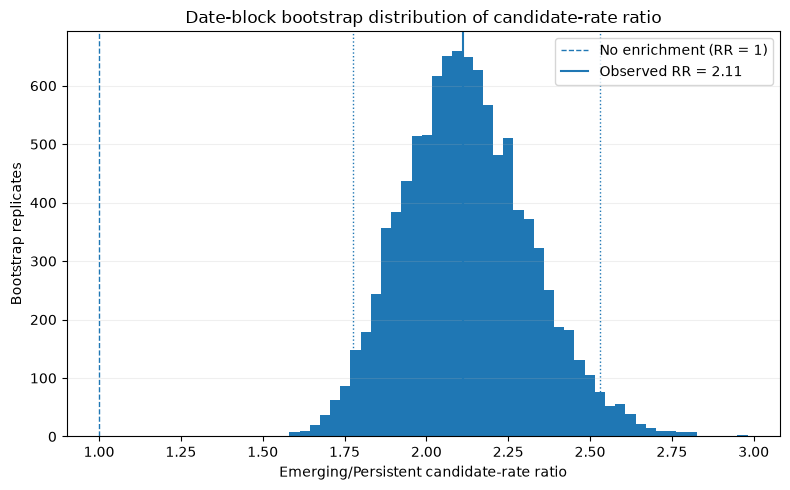

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_date_block_bootstrap\t2\figures\01_date_block_bootstrap_risk_ratio.png


In [11]:
# 10. Risk-ratio bootstrap distribution

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    rr_valid,
    bins=45,
)

ax.axvline(
    1.0,
    linestyle="--",
    linewidth=1,
    label="No enrichment (RR = 1)",
)

ax.axvline(
    observed[
        "risk_ratio"
    ],
    linewidth=1.5,
    label=(
        "Observed RR = "
        f"{observed['risk_ratio']:.2f}"
    ),
)

rr_low, rr_high = percentile_ci(
    rr_valid
)

ax.axvline(
    rr_low,
    linestyle=":",
    linewidth=1,
)

ax.axvline(
    rr_high,
    linestyle=":",
    linewidth=1,
)

ax.set_xlabel(
    "Emerging/Persistent candidate-rate ratio"
)

ax.set_ylabel(
    "Bootstrap replicates"
)

ax.set_title(
    "Date-block bootstrap distribution of candidate-rate ratio"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

ax.legend()

plt.tight_layout()

rr_fig_path = (
    FIGURE_DIR
    / "01_date_block_bootstrap_risk_ratio.png"
)

plt.savefig(
    rr_fig_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", rr_fig_path)

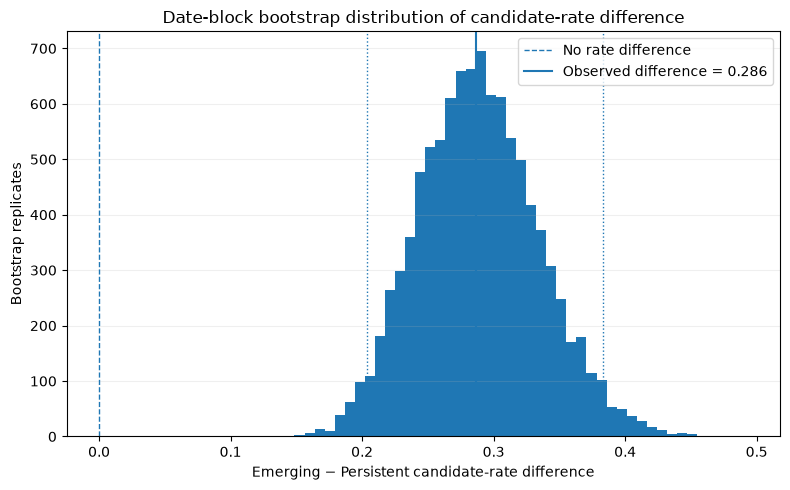

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_date_block_bootstrap\t2\figures\02_date_block_bootstrap_risk_difference.png


In [12]:
# 11. Risk-difference bootstrap distribution

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    rd_valid,
    bins=45,
)

ax.axvline(
    0.0,
    linestyle="--",
    linewidth=1,
    label="No rate difference",
)

ax.axvline(
    observed[
        "risk_difference"
    ],
    linewidth=1.5,
    label=(
        "Observed difference = "
        f"{observed['risk_difference']:.3f}"
    ),
)

rd_low, rd_high = percentile_ci(
    rd_valid
)

ax.axvline(
    rd_low,
    linestyle=":",
    linewidth=1,
)

ax.axvline(
    rd_high,
    linestyle=":",
    linewidth=1,
)

ax.set_xlabel(
    "Emerging − Persistent candidate-rate difference"
)

ax.set_ylabel(
    "Bootstrap replicates"
)

ax.set_title(
    "Date-block bootstrap distribution of candidate-rate difference"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

ax.legend()

plt.tight_layout()

rd_fig_path = (
    FIGURE_DIR
    / "02_date_block_bootstrap_risk_difference.png"
)

plt.savefig(
    rd_fig_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", rd_fig_path)

# PART E — Date-level descriptive audit

This table helps explain whether the overall enrichment is supported across many dates or driven by one exceptional day.

It is descriptive only because some dates have very few Emerging-3 events.

In [13]:
# 12. Daily candidate rates

daily_wide = (
    daily_counts_long
    .pivot(
        index="event_date",
        columns="research_group",
        values=[
            "events",
            "candidates",
        ],
    )
)

daily_wide.columns = [
    f"{a}__{b}"
    for a, b
    in daily_wide.columns
]

daily_wide = (
    daily_wide
    .fillna(0)
    .reset_index()
)

for group in [
    "Emerging-3",
    "Persistent",
]:
    events_col = (
        f"events__{group}"
    )

    cand_col = (
        f"candidates__{group}"
    )

    rate_col = (
        f"rate__{group}"
    )

    daily_wide[
        rate_col
    ] = np.where(
        daily_wide[
            events_col
        ] > 0,
        daily_wide[
            cand_col
        ]
        / daily_wide[
            events_col
        ],
        np.nan,
    )

daily_wide[
    "daily_rate_difference"
] = (
    daily_wide[
        "rate__Emerging-3"
    ]
    - daily_wide[
        "rate__Persistent"
    ]
)

display(
    daily_wide
)

,event_date,events__Emerging-3,events__Persistent,candidates__Emerging-3,candidates__Persistent,rate__Emerging-3,rate__Persistent,daily_rate_difference
0,2026-08-02,4,31,4,17,1.000000,0.548387,0.451613
1,2026-08-04,5,18,5,13,1.000000,0.722222,0.277778
2,2026-08-05,30,31,12,12,0.400000,0.387097,0.012903
3,2026-08-06,17,44,13,12,0.764706,0.272727,0.491979
4,2026-08-07,10,50,8,17,0.800000,0.340000,0.460000
5,2026-08-08,6,56,4,19,0.666667,0.339286,0.327381
6,2026-08-09,7,48,7,13,1.000000,0.270833,0.729167
7,2026-08-10,13,64,7,18,0.538462,0.281250,0.257212
8,2026-08-11,6,63,3,21,0.500000,0.333333,0.166667
9,2026-08-12,4,43,3,9,0.750000,0.209302,0.540698


In [14]:
# 13. Dates with both groups represented

both_group_days = (
    daily_wide[
        (
            daily_wide[
                "events__Emerging-3"
            ] > 0
        )
        &
        (
            daily_wide[
                "events__Persistent"
            ] > 0
        )
    ]
    .copy()
)

n_positive_days = int(
    (
        both_group_days[
            "daily_rate_difference"
        ] > 0
    ).sum()
)

n_negative_days = int(
    (
        both_group_days[
            "daily_rate_difference"
        ] < 0
    ).sum()
)

n_tied_days = int(
    (
        both_group_days[
            "daily_rate_difference"
        ] == 0
    ).sum()
)

daily_direction_summary = pd.DataFrame({
    "metric": [
        "Dates with both groups",
        "Dates Emerging rate > Persistent rate",
        "Dates Emerging rate < Persistent rate",
        "Dates tied",
    ],
    "value": [
        len(both_group_days),
        n_positive_days,
        n_negative_days,
        n_tied_days,
    ],
})

display(
    daily_direction_summary
)

,metric,value
0,Dates with both groups,29
1,Dates Emerging rate > Persistent rate,27
2,Dates Emerging rate < Persistent rate,2
3,Dates tied,0


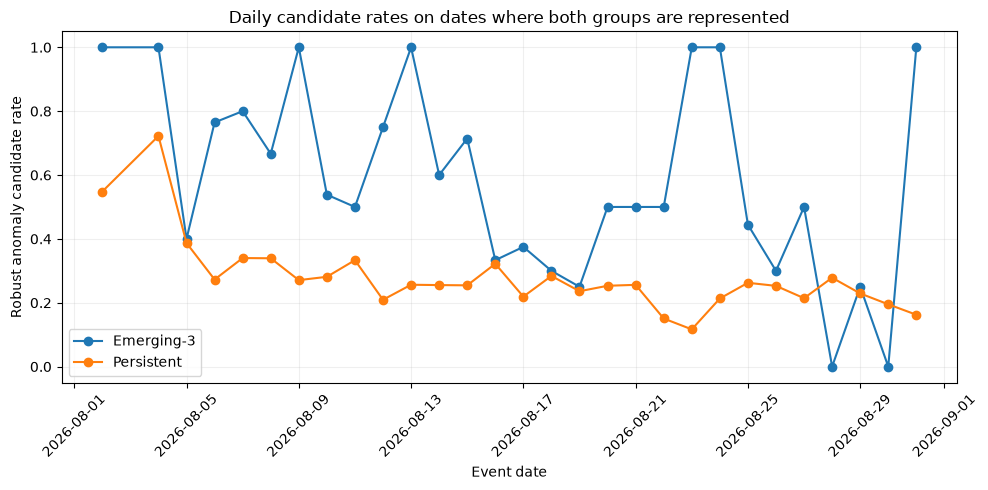

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_date_block_bootstrap\t2\figures\03_daily_candidate_rates.png


In [15]:
# 14. Daily-rate descriptive figure

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    both_group_days[
        "event_date"
    ],
    both_group_days[
        "rate__Emerging-3"
    ],
    marker="o",
    label="Emerging-3",
)

ax.plot(
    both_group_days[
        "event_date"
    ],
    both_group_days[
        "rate__Persistent"
    ],
    marker="o",
    label="Persistent",
)

ax.set_xlabel(
    "Event date"
)

ax.set_ylabel(
    "Robust anomaly candidate rate"
)

ax.set_title(
    "Daily candidate rates on dates where both groups are represented"
)

ax.grid(
    alpha=0.2
)

ax.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()

daily_fig_path = (
    FIGURE_DIR
    / "03_daily_candidate_rates.png"
)

plt.savefig(
    daily_fig_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", daily_fig_path)

# PART F — Optional sensitivity: 3-day moving-block bootstrap

The primary result remains the date-block bootstrap above.

As an additional robustness check, a 3-day moving-block bootstrap preserves short-range serial dependence across adjacent dates better than sampling individual dates.

This does **not** replace the primary result.

In [16]:
# 15. Build complete daily count matrix

date_index = pd.date_range(
    known[
        "event_date"
    ].min(),
    known[
        "event_date"
    ].max(),
    freq="D",
)

daily_matrix = (
    pd.DataFrame(
        index=date_index
    )
)

for group, prefix in [
    (
        "Emerging-3",
        "em",
    ),
    (
        "Persistent",
        "pe",
    ),
]:
    subset = (
        daily_counts_long[
            daily_counts_long[
                "research_group"
            ].eq(group)
        ]
        .set_index(
            "event_date"
        )[
            [
                "events",
                "candidates",
            ]
        ]
        .reindex(
            date_index,
            fill_value=0,
        )
    )

    daily_matrix[
        f"{prefix}_events"
    ] = subset[
        "events"
    ]

    daily_matrix[
        f"{prefix}_candidates"
    ] = subset[
        "candidates"
    ]

daily_matrix = (
    daily_matrix
    .reset_index()
    .rename(
        columns={
            "index": "event_date"
        }
    )
)

display(
    daily_matrix.head()
)

,event_date,em_events,em_candidates,pe_events,pe_candidates
0,2026-08-02,4,4,31,17
1,2026-08-03,0,0,0,0
2,2026-08-04,5,5,18,13
3,2026-08-05,30,12,31,12
4,2026-08-06,17,13,44,12


In [17]:
# 16. 3-day moving-block bootstrap

BLOCK_LENGTH = 3
N_BOOT_MBB = 10_000
MBB_SEED = 2027

rng_mbb = np.random.default_rng(
    MBB_SEED
)

matrix_values = daily_matrix[
    [
        "em_events",
        "em_candidates",
        "pe_events",
        "pe_candidates",
    ]
].to_numpy(
    dtype=float
)

n_days = len(matrix_values)

valid_starts = np.arange(
    0,
    n_days - BLOCK_LENGTH + 1,
)

mbb_rows = []

for i in range(
    N_BOOT_MBB
):
    chosen_rows = []

    while len(
        chosen_rows
    ) < n_days:
        start = int(
            rng_mbb.choice(
                valid_starts
            )
        )

        block = matrix_values[
            start:
            start + BLOCK_LENGTH
        ]

        chosen_rows.extend(
            block.tolist()
        )

    sample = np.asarray(
        chosen_rows[
            :n_days
        ],
        dtype=float,
    )

    totals = sample.sum(
        axis=0
    )

    metrics = compute_metrics_from_counts(
        int(totals[0]),
        int(totals[1]),
        int(totals[2]),
        int(totals[3]),
    )

    mbb_rows.append({
        "bootstrap_id": i,
        **metrics,
    })

moving_block_bootstrap = pd.DataFrame(
    mbb_rows
)

mbb_summary_rows = []

for col, (
    label,
    observed_value,
) in metric_map.items():
    low, high = percentile_ci(
        moving_block_bootstrap[
            col
        ]
    )

    mbb_summary_rows.append({
        "metric": label,
        "observed": float(
            observed_value
        ),
        "mbb_2.5%": low,
        "mbb_97.5%": high,
        "block_length_days": BLOCK_LENGTH,
        "bootstrap_replicates": int(
            moving_block_bootstrap[
                col
            ]
            .notna()
            .sum()
        ),
    })

moving_block_summary = pd.DataFrame(
    mbb_summary_rows
)

display(
    moving_block_summary
)

,metric,observed,mbb_2.5%,mbb_97.5%,block_length_days,bootstrap_replicates
0,Emerging-3 candidate rate,0.543779,0.437956,0.633509,3,10000
1,Persistent candidate rate,0.257436,0.230879,0.294154,3,10000
2,Candidate-rate ratio Emerging/Persistent,2.112284,1.733120,2.466148,3,10000
3,Candidate-rate difference Emerging-Persistent,0.286342,0.188597,0.370318,3,10000


# PART G — Final reporting table

For the thesis, prioritize:

1. observed Emerging-3 candidate rate;
2. observed Persistent candidate rate;
3. observed risk ratio;
4. date-block bootstrap 95% interval;
5. observed risk difference;
6. date-block bootstrap 95% interval.

The 3-day moving-block result can be reported as a robustness/sensitivity check.

Do not present the bootstrap directional fraction as an exact p-value.

In [18]:
# 17. Combine primary and sensitivity intervals

final_report = (
    bootstrap_summary
    .merge(
        moving_block_summary[
            [
                "metric",
                "mbb_2.5%",
                "mbb_97.5%",
            ]
        ],
        on="metric",
        how="left",
        validate="one_to_one",
    )
)

display(
    final_report
)

,metric,observed,bootstrap_2.5%,bootstrap_97.5%,bootstrap_replicates,mbb_2.5%,mbb_97.5%
0,Emerging-3 candidate rate,0.543779,0.461903,0.640449,10000,0.437956,0.633509
1,Persistent candidate rate,0.257436,0.234479,0.283207,10000,0.230879,0.294154
2,Candidate-rate ratio Emerging/Persistent,2.112284,1.774343,2.531480,10000,1.733120,2.466148
3,Candidate-rate difference Emerging-Persistent,0.286342,0.203437,0.383012,10000,0.188597,0.370318


In [19]:
# 18. Export

bootstrap.to_csv(
    EXPORT_DIR
    / "date_block_bootstrap_replicates.csv",
    index=False,
)

bootstrap_summary.to_csv(
    EXPORT_DIR
    / "date_block_bootstrap_summary.csv",
    index=False,
)

directional_summary.to_csv(
    EXPORT_DIR
    / "bootstrap_directional_stability.csv",
    index=False,
)

daily_counts_long.to_csv(
    EXPORT_DIR
    / "daily_group_candidate_counts.csv",
    index=False,
)

daily_wide.to_csv(
    EXPORT_DIR
    / "daily_candidate_rates.csv",
    index=False,
)

daily_direction_summary.to_csv(
    EXPORT_DIR
    / "daily_direction_summary.csv",
    index=False,
)

moving_block_bootstrap.to_csv(
    EXPORT_DIR
    / "moving_block_3day_bootstrap_replicates.csv",
    index=False,
)

moving_block_summary.to_csv(
    EXPORT_DIR
    / "moving_block_3day_bootstrap_summary.csv",
    index=False,
)

final_report.to_csv(
    EXPORT_DIR
    / "final_enrichment_uncertainty_table.csv",
    index=False,
)

metadata = {
    "notebook": "27_final_date_block_bootstrap",
    "model_development": "frozen before this notebook",
    "candidate_rule": (
        "actual hotspot AND 5-seed ensemble median rank >= 0.80 "
        "AND at least 4/5 seed ranks >= 0.80"
    ),
    "primary_uncertainty_method": "date-block bootstrap",
    "primary_bootstrap_replicates": N_BOOT,
    "primary_bootstrap_seed": BOOT_SEED,
    "primary_ci": "percentile 95%",
    "sensitivity_method": "3-day moving-block bootstrap",
    "sensitivity_replicates": N_BOOT_MBB,
    "interpretation_limit": (
        "Emerging/Persistent is post-hoc behavioral validation, "
        "not ignition-cause ground truth."
    ),
}

(
    EXPORT_DIR
    / "nb27_methodology_metadata.json"
).write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved outputs to:", EXPORT_DIR)

Saved outputs to: c:\Users\Asus\Documents\skripsi-karhut\model_results\final_date_block_bootstrap\t2\exports


In [20]:
# 19. Automatic final review

def get_summary_value(
    df,
    metric_name,
    col,
):
    return float(
        df.loc[
            df[
                "metric"
            ].eq(
                metric_name
            ),
            col,
        ].iloc[0]
    )

rr_metric = (
    "Candidate-rate ratio Emerging/Persistent"
)

rd_metric = (
    "Candidate-rate difference Emerging-Persistent"
)

rr_low = get_summary_value(
    bootstrap_summary,
    rr_metric,
    "bootstrap_2.5%",
)

rr_high = get_summary_value(
    bootstrap_summary,
    rr_metric,
    "bootstrap_97.5%",
)

rd_low = get_summary_value(
    bootstrap_summary,
    rd_metric,
    "bootstrap_2.5%",
)

rd_high = get_summary_value(
    bootstrap_summary,
    rd_metric,
    "bootstrap_97.5%",
)

mbb_rr_low = get_summary_value(
    moving_block_summary,
    rr_metric,
    "mbb_2.5%",
)

mbb_rr_high = get_summary_value(
    moving_block_summary,
    rr_metric,
    "mbb_97.5%",
)

print("=== NB27 FINAL BLOCK-BOOTSTRAP REVIEW ===")
print()

print(
    f"Emerging-3 candidate rate: "
    f"{em_candidates}/{em_events} "
    f"= {observed['emerging_rate']:.3%}"
)

print(
    f"Persistent candidate rate: "
    f"{pe_candidates}/{pe_events} "
    f"= {observed['persistent_rate']:.3%}"
)

print()
print(
    f"Observed risk ratio: "
    f"{observed['risk_ratio']:.3f}"
)

print(
    f"Date-block bootstrap 95% CI: "
    f"[{rr_low:.3f}, {rr_high:.3f}]"
)

print(
    f"3-day moving-block 95% CI: "
    f"[{mbb_rr_low:.3f}, {mbb_rr_high:.3f}]"
)

print()
print(
    f"Observed rate difference: "
    f"{observed['risk_difference']:.3%}"
)

print(
    f"Date-block bootstrap 95% CI: "
    f"[{rd_low:.3%}, {rd_high:.3%}]"
)

print()
print(
    "Dates with both groups:",
    len(both_group_days),
)

print(
    "Emerging rate > Persistent rate on:",
    n_positive_days,
    "dates",
)

print(
    "Emerging rate < Persistent rate on:",
    n_negative_days,
    "dates",
)

print(
    "Tied:",
    n_tied_days,
    "dates",
)

print()
print(
    "No model tuning or candidate-threshold changes were performed in NB27."
)

=== NB27 FINAL BLOCK-BOOTSTRAP REVIEW ===

Emerging-3 candidate rate: 118/217 = 54.378%
Persistent candidate rate: 476/1849 = 25.744%

Observed risk ratio: 2.112
Date-block bootstrap 95% CI: [1.774, 2.531]
3-day moving-block 95% CI: [1.733, 2.466]

Observed rate difference: 28.634%
Date-block bootstrap 95% CI: [20.344%, 38.301%]

Dates with both groups: 29
Emerging rate > Persistent rate on: 27 dates
Emerging rate < Persistent rate on: 2 dates
Tied: 0 dates

No model tuning or candidate-threshold changes were performed in NB27.


# Thesis wording template

After inspecting the executed output, report the exact numbers from the final review.

A suitable structure is:

> Using the candidate rule fixed before the enrichment analysis, X% of Emerging-3 hotspot cell-days and Y% of Persistent hotspot cell-days were identified as robust contextual anomalies. The observed candidate-rate ratio was RR. A date-block bootstrap that resampled whole event dates produced a 95% interval of [L, U], accounting for dependence among hotspot observations occurring on the same date. A 3-day moving-block sensitivity analysis produced a qualitatively consistent interval of [L2, U2].

Then add:

> Emerging-3 was used only for post-hoc behavioral validation and was not provided to the self-supervised model during training.

Do not interpret this as evidence of anthropogenic or intentional ignition.